<a href="https://colab.research.google.com/github/rrodriperezz/Regresion_lineal/blob/main/linear_regression_security_incident.ipynb">Open this notebook in Google Colab</a>

# Linear Regression: Cost of a Security Incident

Linear regression fundamentals, shown with a simple cybersecurity use case.

### 0. Imports

In [1]:
# Install external libraries
!pip install -q pandas numpy matplotlib scikit-learn

### 1. Generating the dataset

A random dataset is generated to simulate:
- `X`: number of devices affected by a security incident
- `y`: cost of the security incident

The goal is a dataset that reflects realistic incident scenarios.

In [2]:
import numpy as np

np.random.seed(42)  # reproducible results
X = 2 * np.random.rand(75, 1)
y = 4 + 3 * X + np.random.randn(75, 1)

print("Dataset size:", len(X))

Dataset size: 75


### 2. Visualizing the dataset

In [3]:
import matplotlib.pyplot as plt
%matplotlib inline

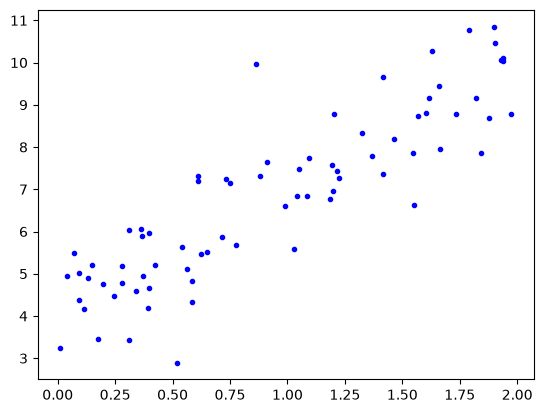

In [4]:
plt.plot(X, y, "b.")
plt.show()

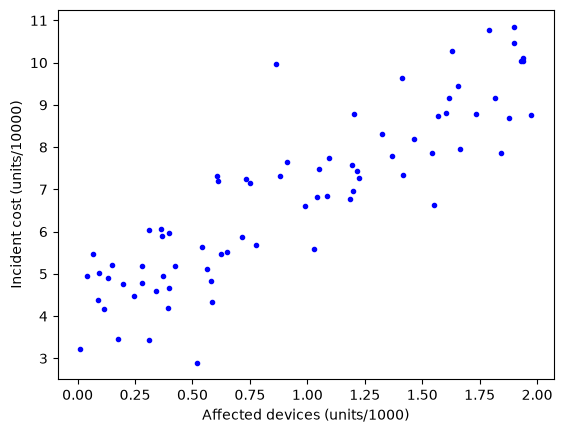

In [5]:
plt.plot(X, y, "b.")
plt.xlabel("Affected devices (units/1000)")
plt.ylabel("Incident cost (units/10000)")
plt.show()

### 3. Transforming the dataset

In [6]:
import pandas as pd

In [7]:
data = {'affected_devices': X.flatten(), 'cost': y.flatten()}
df = pd.DataFrame(data)
df.head(10)

,affected_devices,cost
0,0.749080,7.141573
1,1.901429,10.459284
2,1.463988,8.184798
3,1.197317,6.968474
4,0.312037,3.427959
5,0.311989,6.035614
6,0.116167,4.170770
7,1.732352,8.786674
8,1.202230,8.786406
9,1.416145,7.350228


In [8]:
# Scale the number of affected devices
df['affected_devices'] = df['affected_devices'] * 1000
df['affected_devices'] = df['affected_devices'].astype('int')
# Scale the cost
df['cost'] = df['cost'] * 10000
df['cost'] = df['cost'].astype('int')
df.head(10)

,affected_devices,cost
0,749,71415
1,1901,104592
2,1463,81847
3,1197,69684
4,312,34279
5,311,60356
6,116,41707
7,1732,87866
8,1202,87864
9,1416,73502


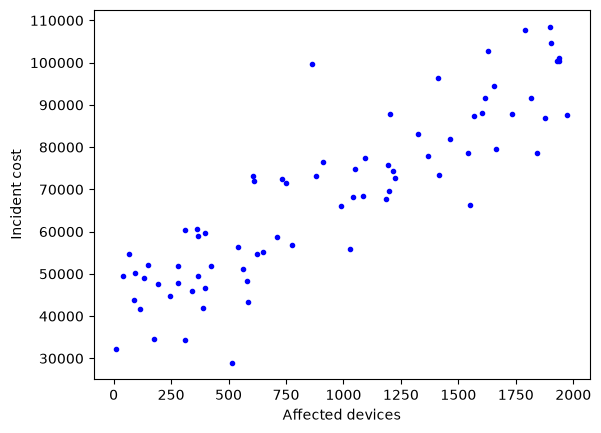

In [9]:
# Plot the dataset
plt.plot(df['affected_devices'], df['cost'], "b.")
plt.xlabel("Affected devices")
plt.ylabel("Incident cost")
plt.show()

## 4. Building the linear regression model
This step trains a linear regression model with `sklearn`.
The goal is to learn the relationship between:
- `X`: affected devices
- `y`: cost of the security incident

In [10]:
from sklearn.linear_model import LinearRegression

In [11]:
# Build the model and fit the hypothesis function
lin_reg = LinearRegression()
lin_reg.fit(df['affected_devices'].values.reshape(-1, 1), df['cost'].values)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[29.07]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.094e+04
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[5265.17]


In [12]:
# Parameter theta 0
lin_reg.intercept_

np.float64(40941.74996192478)

In [13]:
# Parameter theta 1
lin_reg.coef_

array([29.07061447])

In [14]:
# Predict the minimum and maximum values of the training data
X_min_max = np.array([[df["affected_devices"].min()], [df["affected_devices"].max()]])
y_train_pred = lin_reg.predict(X_min_max)

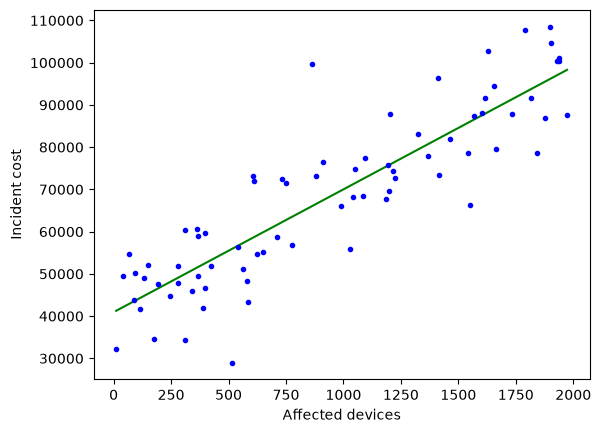

In [15]:
# Plot the fitted hypothesis function
plt.plot(X_min_max, y_train_pred, "g-")
plt.plot(df['affected_devices'], df['cost'], "b.")
plt.xlabel("Affected devices")
plt.ylabel("Incident cost")
plt.show()

## 5. Prediction and model visualization

The trained model predicts the incident cost (`y_pred`) from the input data (`X`).
The regression line is plotted with the original data to evaluate the fit.


In [16]:
x_new = np.array([[1300]])  # 1300 affected devices

# Predict the cost of the incident
cost = lin_reg.predict(x_new)

print("Predicted incident cost:", int(cost[0]), "€")

Predicted incident cost: 78733 €


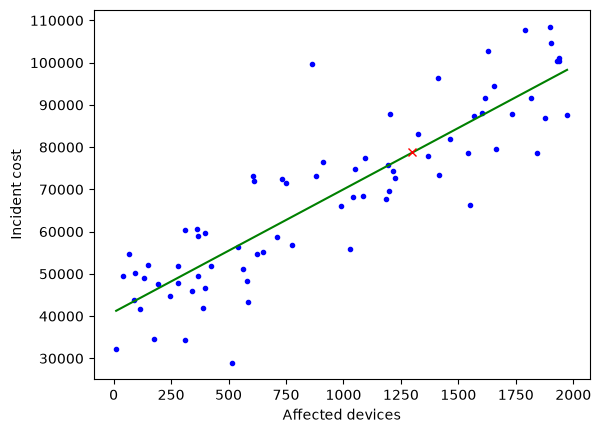

In [17]:
plt.plot(df['affected_devices'], df['cost'], "b.")
plt.plot(X_min_max, y_train_pred, "g-")
plt.plot(x_new, cost, "rx")
plt.xlabel("Affected devices")
plt.ylabel("Incident cost")
plt.show()

In [18]:
x_new = np.array([[1100]])  # 1100 affected devices

# Predict the cost of the incident
cost = lin_reg.predict(x_new)

print("Predicted incident cost:", int(cost[0]), "€")

Predicted incident cost: 72919 €


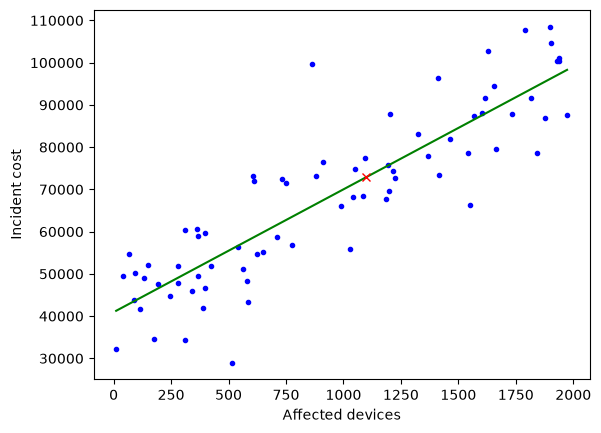

In [19]:
plt.plot(df['affected_devices'], df['cost'], "b.")
plt.plot(X_min_max, y_train_pred, "g-")
plt.plot(x_new, cost, "rx")
plt.xlabel("Affected devices")
plt.ylabel("Incident cost")
plt.show()

In [20]:
x2_new = np.array([[1300]])  # 1300 affected devices

# Predict the cost of the incident
cost2 = lin_reg.predict(x2_new)

print("Predicted incident cost:", int(cost2[0]), "€")

Predicted incident cost: 78733 €


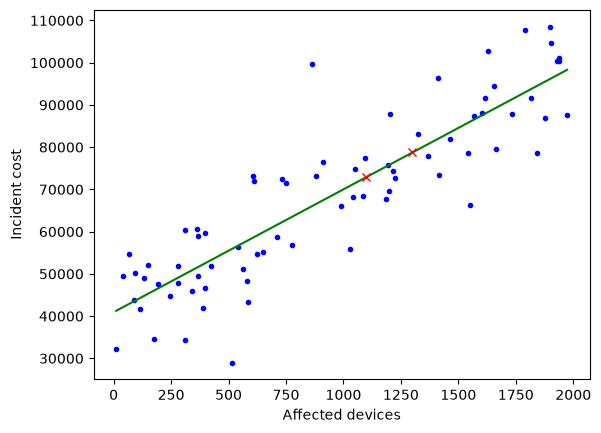

In [21]:
plt.plot(df['affected_devices'], df['cost'], "b.")
plt.plot(X_min_max, y_train_pred, "g-")
plt.plot(x_new, cost, "rx")
plt.plot(x2_new, cost2, "rx")
plt.xlabel("Affected devices")
plt.ylabel("Incident cost")
plt.show()